# ML1 – Uber Fare Prediction
Predict `fare_amount` using **Linear Regression** and **Random Forest**.
Tasks: 1) pre-process, 2) outliers, 3) correlation, 4) two models, 5) compare R², RMSE.

### Step 1: Load data

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

df = pd.read_csv("uber.csv")
print(df.shape)
df.head()

(200000, 9)


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


### Step 2: Pre-process
- Drop unused columns and missing values
- Remove impossible values (negative fare, bad passenger count, coordinates outside valid range)
- Convert date to useful features
- Create **distance** from coordinates (haversine formula) – fare mainly depends on distance

In [4]:
df = df.drop(columns=["Unnamed: 0", "key"], errors="ignore")
print("Missing values:\n", df.isnull().sum())
df = df.dropna()

# remove invalid rows
df = df[(df.fare_amount > 0) & (df.passenger_count.between(1, 6))]
df = df[df.pickup_latitude.between(-90, 90) & df.dropoff_latitude.between(-90, 90)]
df = df[df.pickup_longitude.between(-180, 180) & df.dropoff_longitude.between(-180, 180)]

# date -> features
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"])
df["year"] = df.pickup_datetime.dt.year
df["hour"] = df.pickup_datetime.dt.hour
df["dayofweek"] = df.pickup_datetime.dt.dayofweek

# haversine distance in km
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

df["distance_km"] = haversine(df.pickup_latitude, df.pickup_longitude, df.dropoff_latitude, df.dropoff_longitude)
df = df[df.distance_km > 0]            # trips with zero distance are errors
print("Shape after cleaning:", df.shape)

Missing values:
 fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64
Shape after cleaning: (193644, 11)


### Step 3: Identify and remove outliers (IQR method)
A value is an outlier if it is below `Q1 - 1.5*IQR` or above `Q3 + 1.5*IQR`.

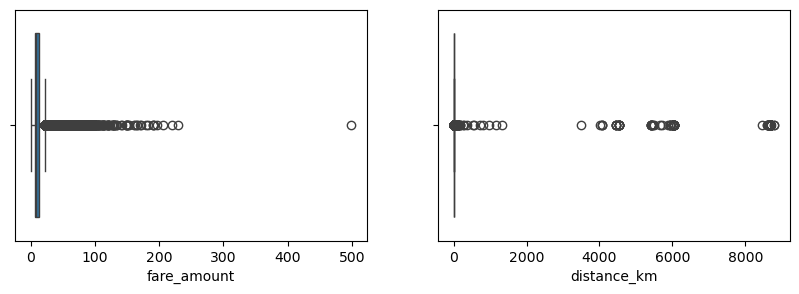

Outliers removed: 24625  | Remaining rows: 169019


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
sns.boxplot(x=df.fare_amount, ax=ax[0]); sns.boxplot(x=df.distance_km, ax=ax[1])
plt.show()

def remove_outliers(d, col):
    q1, q3 = d[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    return d[d[col].between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)]

before = len(df)
for col in ["fare_amount", "distance_km"]:
    df = remove_outliers(df, col)
print(f"Outliers removed: {before - len(df)}  | Remaining rows: {len(df)}")

### Step 4: Correlation

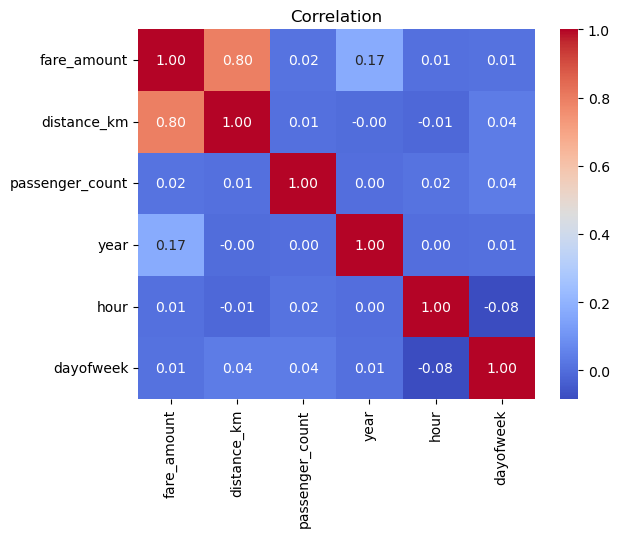

In [8]:
cols = ["fare_amount", "distance_km", "passenger_count", "year", "hour", "dayofweek"]
sns.heatmap(df[cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation"); plt.show()

### Step 5: Split data and train both models

In [10]:
features = ["distance_km", "passenger_count", "year", "hour", "dayofweek"]
X, y = df[features], df["fare_amount"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

lr = LinearRegression().fit(X_train, y_train)
rf = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42).fit(X_train, y_train)

### Step 6: Evaluate and compare

In [12]:
results = {}
for name, model in {"Linear Regression": lr, "Random Forest": rf}.items():
    pred = model.predict(X_test)
    results[name] = {"R2": r2_score(y_test, pred),
                     "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
                     "MAE": mean_absolute_error(y_test, pred)}
print(pd.DataFrame(results).T.round(4))

                       R2    RMSE     MAE
Linear Regression  0.6687  2.1406  1.5289
Random Forest      0.6669  2.1464  1.5341
